<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/jobsheet_pbl/JS14_PBL_244107020095_RACHMAD_FEBRIANANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS14 — Convolutional Neural Network (1D-CNN) pada Data Properti

Jobsheet asli memakai CNN 2D untuk citra (cat/dog, CIFAR-10, MNIST). Dataset PBL
RumahPoint **tidak memiliki citra properti**, sehingga CNN 2D tidak bisa diterapkan
secara wajar. Sebagai adaptasi yang tetap memakai konsep konvolusi, notebook ini
memakai **Conv1D**: setiap properti diperlakukan sebagai "urutan" nilai fitur, dan
filter konvolusi belajar kombinasi lokal antarfitur yang berdekatan.

Yang dipertahankan dari jobsheet asli: lapisan konvolusi, pooling, BatchNormalization,
Dropout, augmentasi (di sini tidak relevan), serta perbandingan dengan model baseline.

## Langkah 1 — Data dan Representasi Urutan Fitur

Urutan fitur disusun berdasarkan domain:

1. `luas_m2`
2. `luas_bangunan`
3. `jumlah_kamar`
4. `jumlah_kamar_mandi`
5. `lokasi_freq`
6. `kondisi = Baru`
7. `kondisi = Bekas`
8. `kondisi = Tidak diketahui`

Dengan begitu, filter berukuran 2–3 dapat menangkap kombinasi seperti
"luas tanah–luas bangunan" atau "kamar–kamar mandi".

In [1]:
import os, warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

sns.set_theme(style='whitegrid', palette='muted')
RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)

df = pd.read_csv('dataset/properti_multi_kota.csv').drop_duplicates()
df = df[(df['luas_m2'] >= 10) & (df['luas_m2'] <= 2000)]
df = df[df['luas_bangunan'].isna() |
        ((df['luas_bangunan'] >= 10) & (df['luas_bangunan'] <= 2000))]
df = df[df['harga'].between(50_000_000, 100_000_000_000)]
df = df[df['jumlah_kamar'].isna() | (df['jumlah_kamar'] <= 20)]
df = df[df['jumlah_kamar_mandi'].isna() | (df['jumlah_kamar_mandi'] <= 20)]

FITUR_NUM = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']
df[FITUR_NUM] = df[FITUR_NUM].fillna(df[FITUR_NUM].median())
df['lokasi_bersih'] = df['lokasi'].str.strip().str.title()
df['lokasi_freq'] = df['lokasi_bersih'].map(df['lokasi_bersih'].value_counts(normalize=True))

TAHUN_INI = 2026
tahun = df['usia_bangunan'] > 100
df.loc[tahun, 'usia_bangunan'] = TAHUN_INI - df.loc[tahun, 'usia_bangunan']
df.loc[~df['usia_bangunan'].between(0, 100) & df['usia_bangunan'].notna(),
       'usia_bangunan'] = np.nan
df['kondisi'] = np.where(df['usia_bangunan'].isna(), 'Tidak diketahui',
                 np.where(df['usia_bangunan'] <= 3, 'Baru', 'Bekas'))

q1, q2 = df['harga'].quantile([1 / 3, 2 / 3])
df['kelas_harga'] = np.where(df['harga'] < q1, 'Murah',
                     np.where(df['harga'] <= q2, 'Sedang', 'Mahal'))

kondisi_ohe = pd.get_dummies(df['kondisi'], prefix='kondisi', dtype=float)
FITUR = FITUR_NUM + ['lokasi_freq'] + list(kondisi_ohe.columns)
X_tab = pd.concat([df[FITUR_NUM + ['lokasi_freq']].reset_index(drop=True),
                   kondisi_ohe.reset_index(drop=True)], axis=1)

le = LabelEncoder()
y = le.fit_transform(df['kelas_harga'])

scaler = StandardScaler().fit(X_tab)
X_scaled = scaler.transform(X_tab)

# (n_baris, n_fitur, 1) -> satu "saluran" untuk Conv1D
X_seq = X_scaled.reshape(len(X_scaled), len(FITUR), 1)

X_tr, X_te, y_tr, y_te = train_test_split(
    X_seq, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print('Fitur (urutan):', FITUR)
print('Shape train:', X_tr.shape, '| test:', X_te.shape)
print('Kelas:', list(le.classes_))

Fitur (urutan): ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'lokasi_freq', 'kondisi_Baru', 'kondisi_Bekas', 'kondisi_Tidak diketahui']
Shape train: (44936, 8, 1) | test: (11234, 8, 1)
Kelas: ['Mahal', 'Murah', 'Sedang']


## Langkah 2 — Model 1D-CNN

Arsitektur:

- `Conv1D(32, kernel 2)` → BatchNorm → `MaxPooling1D(2)`
- `Conv1D(64, kernel 2)` → BatchNorm → `GlobalMaxPooling1D`
- `Dense(64)` → Dropout(0.3) → `Dense(3, softmax)`

`GlobalMaxPooling1D` dipakai agar model tidak bergantung pada panjang urutan tertentu.

In [2]:
def buat_cnn(kernel_size=2, filter1=32, filter2=64):
    model = models.Sequential([
        layers.Input((X_tr.shape[1], 1)),
        layers.Conv1D(filter1, kernel_size, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Conv1D(filter2, kernel_size, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.GlobalMaxPooling1D(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(3, activation='softmax'),
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

cnn = buat_cnn()
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 8, 32)          │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 32)          │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 4, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 4, 64)          │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 4, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,995 (35.14 KB)

 Trainable params: 8,803 (34.39 KB)

 Non-trainable params: 192 (768.00 B)

In [3]:
t0 = time.perf_counter()
hist = cnn.fit(X_tr, y_tr, validation_split=0.15, epochs=60, batch_size=256,
               callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=6,
                                                  restore_best_weights=True)],
               verbose=2)
waktu_cnn = time.perf_counter() - t0
print(f'Waktu training: {waktu_cnn:.1f} detik')

Epoch 1/60


150/150 - 3s - 21ms/step - accuracy: 0.6672 - loss: 0.7428 - val_accuracy: 0.6729 - val_loss: 0.9100


Epoch 2/60


150/150 - 1s - 7ms/step - accuracy: 0.7059 - loss: 0.6517 - val_accuracy: 0.6830 - val_loss: 0.7509


Epoch 3/60


150/150 - 1s - 9ms/step - accuracy: 0.7161 - loss: 0.6344 - val_accuracy: 0.7082 - val_loss: 0.6410


... (63 outputs left out)

150/150 - 1s - 8ms/step - accuracy: 0.7436 - loss: 0.5803 - val_accuracy: 0.7388 - val_loss: 0.5864


Epoch 36/60


150/150 - 1s - 6ms/step - accuracy: 0.7417 - loss: 0.5811 - val_accuracy: 0.7386 - val_loss: 0.5862


Waktu training: 44.5 detik


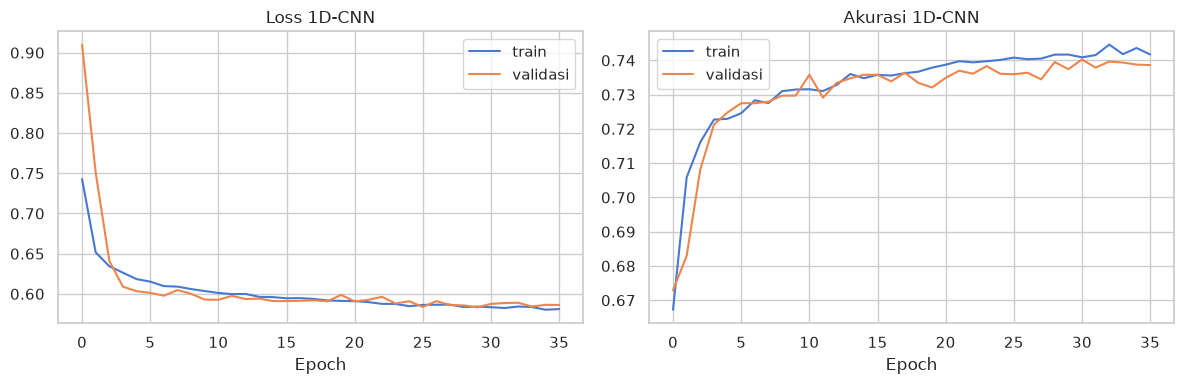

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.history['loss'], label='train')
ax[0].plot(hist.history['val_loss'], label='validasi')
ax[0].set_title('Loss 1D-CNN')
ax[0].set_xlabel('Epoch'); ax[0].legend()

ax[1].plot(hist.history['accuracy'], label='train')
ax[1].plot(hist.history['val_accuracy'], label='validasi')
ax[1].set_title('Akurasi 1D-CNN')
ax[1].set_xlabel('Epoch'); ax[1].legend()

plt.tight_layout()
plt.show()

In [5]:
pred = cnn.predict(X_te, verbose=0).argmax(axis=1)

print(f'Akurasi test: {accuracy_score(y_te, pred):.4f}')
print()
print(classification_report(y_te, pred, target_names=le.classes_, digits=4))

Akurasi test: 0.7364

              precision    recall  f1-score   support

       Mahal     0.7997    0.8224    0.8109      3744
       Murah     0.7570    0.8195    0.7870      3745
      Sedang     0.6381    0.5674    0.6007      3745

    accuracy                         0.7364     11234
   macro avg     0.7316    0.7364    0.7329     11234
weighted avg     0.7316    0.7364    0.7329     11234



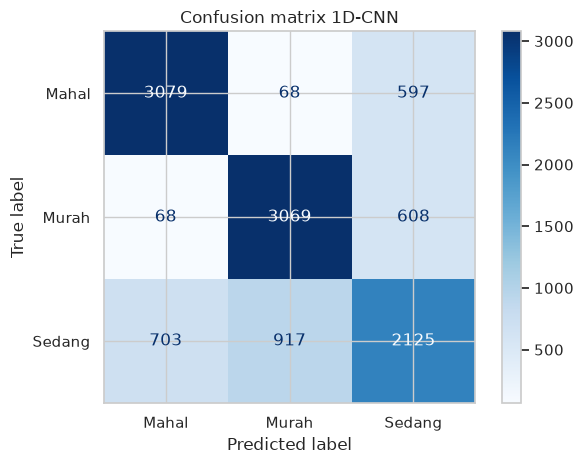

In [6]:
cm = confusion_matrix(y_te, pred)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(cmap='Blues')
plt.title('Confusion matrix 1D-CNN')
plt.tight_layout()
plt.show()

## Langkah 3 — Baseline: MLP pada Fitur yang Sama

Agar terlihat apakah konvolusi benar-benar memberi nilai tambah, data yang sama
dilatih dengan MLP biasa (`Flatten` + Dense).

In [7]:
mlp = models.Sequential([
    layers.Input((X_tr.shape[1], 1)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(3, activation='softmax'),
])
mlp.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

t0 = time.perf_counter()
mlp.fit(X_tr, y_tr, validation_split=0.15, epochs=60, batch_size=256, verbose=0,
        callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=6,
                                           restore_best_weights=True)])
waktu_mlp = time.perf_counter() - t0
pred_mlp = mlp.predict(X_te, verbose=0).argmax(axis=1)

pd.DataFrame([
    {'Model': '1D-CNN', 'Akurasi': accuracy_score(y_te, pred),
     'Waktu (s)': waktu_cnn, 'Parameter': cnn.count_params()},
    {'Model': 'MLP baseline', 'Akurasi': accuracy_score(y_te, pred_mlp),
     'Waktu (s)': waktu_mlp, 'Parameter': mlp.count_params()},
]).round(4)

,Model,Akurasi,Waktu (s),Parameter
0,1D-CNN,0.7364,44.5021,8995
1,MLP baseline,0.7342,32.3219,2755


## Langkah 4 — Tugas: Pengaruh Ukuran Kernel

Kernel 2 menangkap pasangan fitur berdekatan; kernel 3 menangkap tiga fitur sekaligus.
Keduanya diuji dengan 30 epoch pada data yang sama.

In [8]:
baris = []
for kernel in [2, 3, 5]:
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    model = buat_cnn(kernel_size=kernel)
    model.fit(X_tr, y_tr, validation_split=0.15, epochs=30, batch_size=256, verbose=0)
    akurasi = accuracy_score(y_te, model.predict(X_te, verbose=0).argmax(axis=1))
    baris.append({'Kernel size': kernel, 'Akurasi test': akurasi})

pd.DataFrame(baris).round(4)

,Kernel size,Akurasi test
0,2,0.7364
1,3,0.7340
2,5,0.7344


## Langkah 5 — Visualisasi Filter Konvolusi Pertama

Bobot filter lapisan konvolusi pertama menunjukkan pola lokal yang dipelajari model.
Karena hanya ada 8 fitur, pola ini masih bisa ditafsirkan.

Shape bobot Conv1D pertama: (2, 1, 32)


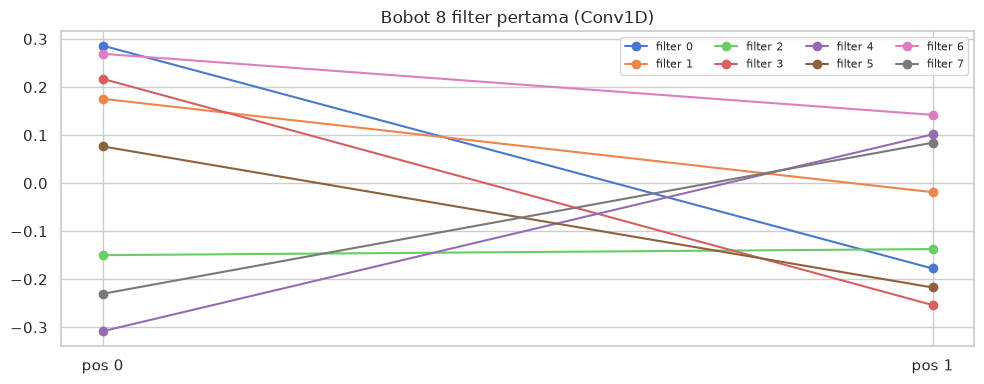

In [9]:
bobot = cnn.layers[0].get_weights()[0]  # (kernel, in_channel, n_filter)
print('Shape bobot Conv1D pertama:', bobot.shape)

plt.figure(figsize=(10, 4))
for i in range(min(8, bobot.shape[2])):
    plt.plot(bobot[:, 0, i], marker='o', label=f'filter {i}')
plt.xticks(range(bobot.shape[0]), [f'pos {j}' for j in range(bobot.shape[0])])
plt.title('Bobot 8 filter pertama (Conv1D)')
plt.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

**Analisis JS14:**

- **1D-CNN** mencapai akurasi uji **0,7364**, hanya **0,2 poin** di atas MLP baseline (0,7342) yang memakai fitur sama. Padahal CNN memakai **8.995 parameter** (3,3 kali MLP) dan waktu training 44,5 detik vs 32,3 detik. Jadi konvolusi **tidak memberi keunggulan berarti** pada data tabular ini.
- Alasannya: urutan 8 fitur tidak punya struktur spasial/temporal nyata. Filter 1D hanya melihat pasangan/triplet fitur yang berdampingan sesuai urutan yang kita susun, bukan pola yang muncul alami dari data.
- CNN 2D yang dipakai jobsheet asli tidak dapat diterapkan karena dataset tidak memiliki citra properti. Memaksakan citra sintetis dari nilai fitur hanya menambah kompleksitas tanpa manfaat.
- **Ukuran kernel**: kernel 2 memberi **0,7364**, kernel 3 **0,7340**, dan kernel 5 **0,7344**. Selisihnya ±0,2 poin — berada dalam rentang variasi antar-run, sehingga tidak ada bukti kernel tertentu lebih baik.
- **BatchNormalization + GlobalMaxPooling** membuat model stabil dan ringkas (9 ribu parameter), tetapi tetap tidak melampaui k-NN (0,755) yang jauh lebih sederhana.
- Bobot filter pertama yang divisualisasikan menunjukkan model mempelajari kombinasi lokal pada posisi fitur luas dan jumlah kamar; namun tanpa struktur nyata, pola ini sulit ditafsirkan sebagai "fitur visual".
- Kesimpulan: untuk data tabular, **Random Forest / gradient boosting** tetap pilihan utama. CNN lebih tepat ketika data benar-benar berbentuk citra, sinyal waktu, atau teks.
